# LoRA and Parameter-Efficient Fine-Tuning

---

Creator: Chung-En Johnny Yu

Content updated: 2026-10-29

Hands-on practice this notebook on your Google Colab:
1. [Click here to open this notebook](https://colab.research.google.com/github/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/06_lora_peft.ipynb)
2. Now, run the code and practice it!

Extends `05_finetuning_classification.ipynb` and `06_finetuning_instructions.ipynb`, which fine-tune a pretrained GPT-2. This notebook explains LoRA with Raschka's Appendix E code, but runs it on CPU without downloading any weights, and adds the parts interviews ask about: when low rank is enough, merging, memory, and choosing between LoRA, full fine-tuning and RAG.

**Sources** — sections taken from Raschka are tagged; everything else is written for this notebook:

| Tag | Source |
|---|---|
| 📗 **[Appendix E]** | Sebastian Raschka, *Build a Large Language Model (From Scratch)*, [Appendix E notebook](https://github.com/rasbt/LLMs-from-scratch/blob/main/appendix-E/01_main-chapter-code/appendix-E.ipynb) — text and LoRA code; GPT model from `ch04/03_kv-cache/gpt_ch04.py` (copied into `06-lora_peft/data/`) |

CPU only, under a minute.

| Part | Content |
|---|---|
| 1 | The menu: prompting, RAG, head-only, full fine-tuning, PEFT |
| 2 | LoRA: the idea |
| 3 | Raschka's LoRA layers, applied to a GPT-2-sized model |
| 4 | Experiment: when is a low-rank update enough? |
| 5 | Merging adapters for zero inference overhead |
| 6 | GPU-memory accounting: full FT vs LoRA vs QLoRA |
| 7 | Instruction SFT: loss masking on the prompt |
| 8 | Interview-style check questions |

---

In [1]:
import math, os, subprocess, sys, urllib.request
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# fetch Raschka's GPT model script: local copy -> this repo -> original repo
local_dir = os.path.join("06-lora_peft", "data")
if os.path.isdir(local_dir):
    sys.path.insert(0, local_dir)
elif not os.path.exists("gpt_ch04.py"):
    for url in ["https://raw.githubusercontent.com/chungenyu6/ai-learning-notebooks/main/02-LLM/live/06-lora_peft/data/gpt_ch04.py",
                "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch04/03_kv-cache/gpt_ch04.py"]:
        try:
            urllib.request.urlretrieve(url, "gpt_ch04.py"); break
        except Exception as e:
            print("could not download", url, e)
try:
    import tiktoken  # noqa: F401  (gpt_ch04 imports it)
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "tiktoken"])
from gpt_ch04 import GPTModel
print("torch", torch.__version__)

torch 2.13.0


## 1. The menu

| Approach | What changes | Typical use | Note |
|---|---|---|---|
| Prompting / few-shot | nothing (only the input) | quick task adaptation | — |
| RAG | nothing; retrieved documents are put in the prompt | fresh or private knowledge, citations | it is **not** fine-tuning |
| Head-only (linear probe) | a new output layer; backbone frozen | classification with little data | the spam classifier in `05_finetuning_classification.ipynb` starts by replacing the output head |
| Full fine-tuning | all weights | maximal adaptation, large data, enough GPUs | — |
| **PEFT: LoRA**, adapters, prefix/prompt tuning | a small number of new parameters; backbone frozen | many tasks on one base model, limited GPU memory | this notebook |

Rule of thumb: **knowledge that changes → RAG; behavior, format, style or a new skill → fine-tuning**; start from the cheapest option that meets the bar.

## 2. Introduction to LoRA

📗 *[Appendix E] §E.1 text and figure*

- Low-rank adaptation (LoRA) modifies a pretrained model to better suit a specific, often smaller, dataset by adjusting only a small, low-rank subset of the model's parameters
- This allows efficient fine-tuning of large models on task-specific data, significantly reducing the computational cost and time required
- Suppose we have a large weight matrix $W$ for a given layer. During backpropagation we learn a $\Delta W$ matrix with how much to update the original weights. In regular fine-tuning:

$$W_{\text{updated}} = W + \Delta W$$

- LoRA ([Hu et al., 2021](https://arxiv.org/abs/2106.09685)) learns an approximation $\Delta W \approx AB$ with two small matrices:

$$W_{\text{updated}} = W + AB$$

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/06-lora_peft/img/lora-1.webp?raw=true" width="550px">

*Figure: weight update in regular fine-tuning vs LoRA; the inner dimension $r$ is a hyperparameter. Source: Raschka, LLMs-from-scratch, Appendix E (original image `appendix-e_compressed/lora-1.webp`).*

- By the distributive law, $x(W+AB) = xW + xAB$: the LoRA matrices can be kept **separate** and applied on the fly, without modifying the pretrained weights at all.

Why it works: the weight changes needed for fine-tuning tend to have **low intrinsic rank**. For a $d\times d$ layer, $AB$ with rank $r$ has $2dr$ parameters instead of $d^2$.

## 3. Parameter-efficient fine-tuning with LoRA

📗 *[Appendix E] §E.4 text, code and figures*

- `LoRALayer` creates the matrices $A$ and $B$, with the scaling hyperparameter `alpha` and the `rank` $r$. `rank` controls the number of additional parameters — the balance between adaptability and efficiency. `alpha` scales the output of the low-rank adaptation, i.e., how strongly it may influence the original layer's output.
- `LinearWithLoRA` wraps an existing `Linear` layer, so the update is applied on top of the pretrained weights:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/06-lora_peft/img/lora-3.webp?raw=true" width="300px">

*Figure: outputs combine the frozen pretrained weights and the LoRA path. Source: Raschka, LLMs-from-scratch, Appendix E (original image `appendix-e_compressed/lora-3.webp`).*

In [2]:
# Source: Raschka, LLMs-from-scratch, appendix-E.ipynb
import math

class LoRALayer(torch.nn.Module):
    def __init__(self, in_dim, out_dim, rank, alpha):
        super().__init__()
        self.A = torch.nn.Parameter(torch.empty(in_dim, rank))
        torch.nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))  # similar to standard weight initialization
        self.B = torch.nn.Parameter(torch.zeros(rank, out_dim))
        self.alpha = alpha
        self.rank = rank

    def forward(self, x):
        # Note: The original chapter didn't include the scaling by self.rank
        # This scaling is not necessary, but it's more canonical and convenient
        # as this lets us compare runs across different ranks without retuning learning rates
        x = (self.alpha / self.rank) * (x @ self.A @ self.B)
        return x


class LinearWithLoRA(torch.nn.Module):
    def __init__(self, linear, rank, alpha):
        super().__init__()
        self.linear = linear
        self.lora = LoRALayer(
            linear.in_features, linear.out_features, rank, alpha
        )

    def forward(self, x):
        return self.linear(x) + self.lora(x)

- Since $B$ is initialized with zeros, $AB = 0$ at the start and adding it does not modify the original weights. Let us check that, and why $B$ (and not both) is zero:

In [3]:
torch.manual_seed(0)
base = nn.Linear(64, 32)
lora = LinearWithLoRA(base, rank=4, alpha=4)
x = torch.randn(5, 64)
assert torch.allclose(lora(x), base(x))
print("at init, LinearWithLoRA == the original Linear (B = 0) ✓")

# If both A and B were zero, no gradient could ever flow into either of them:
both_zero = LoRALayer(64, 32, rank=4, alpha=4)
with torch.no_grad():
    both_zero.A.zero_()
both_zero(x).sum().backward()
print("grad norms with A = B = 0:", both_zero.A.grad.norm().item(), both_zero.B.grad.norm().item())

at init, LinearWithLoRA == the original Linear (B = 0) ✓
grad norms with A = B = 0: 0.0 0.0


To use LoRA on the GPT model, `replace_linear_with_lora` swaps every `Linear` layer for a `LinearWithLoRA` layer — in the attention and feed-forward modules and the output layer:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/06-lora_peft/img/lora-4.webp?raw=true" width="380px">

*Figure: the GPT model with its `Linear` layers replaced. Source: Raschka, LLMs-from-scratch, Appendix E (original image `appendix-e_compressed/lora-4.webp`).*

In [4]:
# Source: Raschka, LLMs-from-scratch, appendix-E.ipynb
def replace_linear_with_lora(model, rank, alpha):
    for name, module in model.named_children():
        if isinstance(module, torch.nn.Linear):
            # Replace the Linear layer with LinearWithLoRA
            setattr(model, name, LinearWithLoRA(module, rank, alpha))
        else:
            # Recursively apply the same function to child modules
            replace_linear_with_lora(module, rank, alpha)

Appendix E applies this to a **pretrained** GPT-2 (124M) whose output layer was replaced by a 2-class spam head. We build the same architecture **without** downloading weights — parameter counts and the zero-init property do not depend on the weights.

In [5]:
# Source: config and head replacement from Raschka, Ch. 4–6 / Appendix E
BASE_CONFIG = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "drop_rate": 0.0,        # Dropout rate
    "qkv_bias": True,        # Query-key-value bias (GPT-2 weights use it)
    "emb_dim": 768, "n_layers": 12, "n_heads": 12,   # gpt2-small (124M)
}
torch.manual_seed(123)
model = GPTModel(BASE_CONFIG).eval()
num_classes = 2
model.out_head = torch.nn.Linear(in_features=768, out_features=num_classes)

In [6]:
# Source: Raschka, LLMs-from-scratch, appendix-E.ipynb; output check added
ids = torch.randint(0, 50257, (2, 16))
with torch.no_grad():
    before = model(ids)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters before: {total_params:,}")

for param in model.parameters():
    param.requires_grad = False

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters after: {total_params:,}")

replace_linear_with_lora(model, rank=16, alpha=16)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable LoRA parameters: {total_params:,}")

with torch.no_grad():
    after = model(ids)
assert torch.allclose(before, after, atol=1e-5)
print("model output unchanged after inserting LoRA ✓")

Total trainable parameters before: 124,441,346
Total trainable parameters after: 0
Total trainable LoRA parameters: 2,666,528
model output unchanged after inserting LoRA ✓


These numbers match Appendix E exactly (124,441,346 → 2,666,528): **almost 50× fewer trainable parameters**. With a pretrained GPT-2, Appendix E then fine-tunes this model on the spam dataset with `AdamW(lr=8e-4)` for 5 epochs (≈12 min on a MacBook M1 CPU, ≈1 min on an A100) and reaches high train/validation/test accuracy. Run the Appendix E notebook on a GPU runtime to reproduce that part.

**Scaling up.** For a Llama-3-8B-style model (32 layers; $W_Q, W_O$: 4096→4096; $W_K, W_V$: 4096→1024 because of GQA; MLP: 4096→14336→4096 with three matrices):

In [7]:
def lora_params(d_in, d_out, r):
    return r * (d_in + d_out)

L = 32
shapes = {"q": (4096, 4096), "k": (4096, 1024), "v": (4096, 1024), "o": (4096, 4096),
          "gate": (4096, 14336), "up": (4096, 14336), "down": (14336, 4096)}
r = 16
lora_total = L * sum(lora_params(i, o, r) for i, o in shapes.values())
lora_qv = L * sum(lora_params(*shapes[k], r) for k in ("q", "v"))
print(f"LoRA r={r}, all linear layers: {lora_total / 1e6:5.1f}M trainable  (~{100 * lora_total / 8.03e9:.2f}% of 8B)")
print(f"LoRA r={r}, only W_q and W_v  : {lora_qv / 1e6:5.1f}M trainable  (the original LoRA paper's choice)")

LoRA r=16, all linear layers:  41.9M trainable  (~0.52% of 8B)
LoRA r=16, only W_q and W_v  :   6.8M trainable  (the original LoRA paper's choice)


## 4. Experiment: when is a low-rank update enough?

*Builds on Raschka's `LinearWithLoRA`.*

A controlled toy: a "pretrained" layer $W_0$; the "target task" needs $W_0 + \Delta W$ where $\Delta W$ has **true rank 4**. We fine-tune with LoRA at ranks 1, 4, 16 and with full fine-tuning.

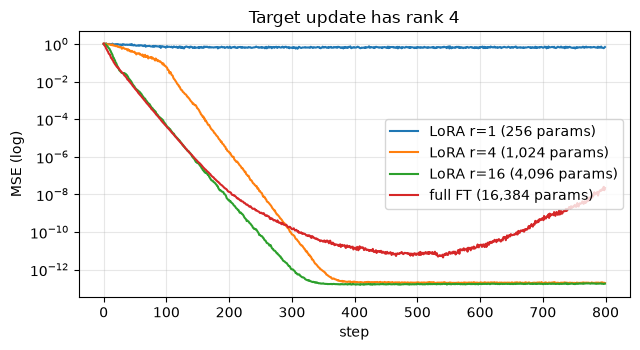

LoRA r=1   trainable    256   final MSE 6.71e-01
LoRA r=4   trainable  1,024   final MSE 1.97e-13
LoRA r=16  trainable  4,096   final MSE 1.79e-13
full FT    trainable 16,384   final MSE 8.30e-09


In [8]:
torch.manual_seed(0)
d_in, d_out, true_rank = 128, 128, 4
W0 = torch.randn(d_out, d_in) / math.sqrt(d_in)
delta = (torch.randn(d_out, true_rank) @ torch.randn(true_rank, d_in)) / math.sqrt(d_in)
W_star = W0 + 0.5 * delta

def task_batch(n=256):
    x = torch.randn(n, d_in)
    return x, x @ W_star.T

def pretrained():
    lin = nn.Linear(d_in, d_out, bias=False)
    with torch.no_grad():
        lin.weight.copy_(W0)
    return lin

def finetune(model, steps=800, lr=1e-2):
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    hist = []
    for _ in range(steps):
        x, y = task_batch()
        loss = F.mse_loss(model(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
        hist.append(loss.item())
    return hist

curves, trainable = {}, {}
for r in (1, 4, 16):
    torch.manual_seed(1)
    base = pretrained()
    base.weight.requires_grad_(False)                      # freeze W0
    m = LinearWithLoRA(base, rank=r, alpha=r)              # alpha = r -> scale 1
    curves[f"LoRA r={r}"] = finetune(m)
    trainable[f"LoRA r={r}"] = sum(p.numel() for p in m.parameters() if p.requires_grad)
full = pretrained()
curves["full FT"] = finetune(full)
trainable["full FT"] = sum(p.numel() for p in full.parameters())

plt.figure(figsize=(6.5, 3.6))
for name, h in curves.items():
    plt.semilogy(h, label=f"{name} ({trainable[name]:,} params)")
plt.xlabel("step"); plt.ylabel("MSE (log)"); plt.title("Target update has rank 4")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
for name, h in curves.items():
    print(f"{name:10s} trainable {trainable[name]:6,}   final MSE {sum(h[-50:]) / 50:.2e}")

Rank 1 cannot represent a rank-4 change and plateaus. Ranks 4 and 16 reach the same tiny error as full fine-tuning with 6–25% of this toy layer's parameters (well under 1% at real model sizes). Real updates are not exactly low-rank, but $r$ = 8–64 is usually enough; tasks that inject a lot of new knowledge (continued pretraining on a new domain or language) are where LoRA falls behind full fine-tuning.

## 5. Merging: zero inference overhead

After training, fold the adapter into the frozen weight. With Raschka's convention ($x\,A\,B$, and `nn.Linear` storing $W$ as `(out, in)`):

$$W_{\text{merged}} = W + \tfrac{\alpha}{r}(AB)^\top .$$

The deployed model is a plain `Linear` layer — **no extra latency**, unlike adapter layers. Or keep adapters separate and hot-swap one small file per task on a shared base model (multi-LoRA serving).

In [9]:
def merge_lora(layer: LinearWithLoRA) -> nn.Linear:
    merged = nn.Linear(layer.linear.in_features, layer.linear.out_features, bias=layer.linear.bias is not None)
    with torch.no_grad():
        delta_w = (layer.lora.alpha / layer.lora.rank) * (layer.lora.A @ layer.lora.B)   # (in, out)
        merged.weight.copy_(layer.linear.weight + delta_w.T)
        if layer.linear.bias is not None:
            merged.bias.copy_(layer.linear.bias)
    return merged

base = pretrained(); base.weight.requires_grad_(False)
m = LinearWithLoRA(base, rank=4, alpha=4)
finetune(m, steps=200)
x = torch.randn(3, d_in)
assert torch.allclose(m(x), merge_lora(m)(x), atol=1e-5)
print("merged Linear gives identical outputs ✓  (one matmul, no adapter path)")

merged Linear gives identical outputs ✓  (one matmul, no adapter path)


## 6. Why LoRA saves so much GPU memory

With mixed-precision Adam, each **trainable** parameter costs about 16 bytes: BF16 weight (2) + BF16 gradient (2) + FP32 master copy (4) + Adam moments (4 + 4). A **frozen** parameter only needs its weight. Activations come on top in both cases.

In [10]:
GiB = 2**30
P = 8.03e9
print(f"full fine-tuning (Adam, mixed precision): {P * 16 / GiB:6.1f} GiB  + activations")
print(f"LoRA (BF16 frozen base)                  : {(P * 2 + lora_total * 16) / GiB:6.1f} GiB  + activations")
print(f"QLoRA (4-bit frozen base)                : {(P * 0.5 + lora_total * 16) / GiB:6.1f} GiB  + activations, quantization metadata")

full fine-tuning (Adam, mixed precision):  119.7 GiB  + activations
LoRA (BF16 frozen base)                  :   15.6 GiB  + activations
QLoRA (4-bit frozen base)                :    4.4 GiB  + activations, quantization metadata


Lower bounds — activations grow with batch × sequence length (gradient checkpointing trades compute to reduce them). QLoRA (Dettmers et al., 2023) quantizes the frozen base to 4-bit NF4 and back-propagates through it into BF16 adapters, making 8B fine-tuning possible on one consumer GPU and ~65B on one 48 GB GPU.

## 7. Instruction SFT: train only on the response

In instruction fine-tuning (main notebook `06_finetuning_instructions.ipynb`) prompt and response are one sequence and the objective is still next-token cross-entropy. The loss is usually **masked on the prompt tokens** (label −100) so the model learns to *produce responses*, not to reproduce user prompts. LoRA and loss masking are independent choices.

In [11]:
prompt_ids = torch.tensor([101, 7, 8, 9, 10, 102])        # "<user> ... <assistant>"
response_ids = torch.tensor([21, 22, 23, 24, 2])           # "... <eos>"
seq = torch.cat([prompt_ids, response_ids])
inputs, labels = seq[:-1], seq[1:].clone()
labels[: len(prompt_ids) - 1] = -100                       # do not train on predicting the prompt
print("inputs:", inputs.tolist())
print("labels:", labels.tolist())
logits = torch.randn(len(inputs), 200)
loss = F.cross_entropy(logits, labels, ignore_index=-100)
print(f"loss averaged over {(labels != -100).sum().item()} response positions only: {loss.item():.3f}")

inputs: [101, 7, 8, 9, 10, 102, 21, 22, 23, 24]
labels: [-100, -100, -100, -100, -100, 21, 22, 23, 24, 2]
loss averaged over 5 response positions only: 6.120


## 8. Check yourself (interview-style)

<details><summary><b>Q1. Explain LoRA: what is trained, how is it initialized, why does it work?</b></summary>

Freeze the pretrained weight $W$ and learn $\Delta W=\frac{\alpha}{r}AB$ with rank $r\ll d$. $A$ is random, $B$ is zero, so training starts exactly from the pretrained model (and gradients still flow, since $A\neq0$). It works because fine-tuning updates have low intrinsic rank. Trainable parameters drop by ~50–1000×, optimizer state drops accordingly, and the adapter can be merged for zero-latency inference.
</details>

<details><summary><b>Q2. How do you choose $r$, $\alpha$, and which layers to adapt?</b></summary>

$r$: 8–64 typical; larger for harder, knowledge-heavy tasks. $\alpha$: often $\alpha=r$ or $2r$; the effective scale is $\alpha/r$ (which lets you compare ranks without retuning the learning rate; rsLoRA argues for $\alpha/\sqrt r$ at large $r$). Layers: the original paper adapted $W_Q, W_V$; current practice (and Appendix E) adapts all linear layers. LoRA usually wants a higher learning rate than full fine-tuning.
</details>

<details><summary><b>Q3. LoRA vs full fine-tuning vs RAG — how do you decide?</b></summary>

RAG for knowledge that changes or must be cited — no training, update the index. LoRA for behavior, format, style or narrow skills with modest data and compute, especially many variants on one base. Full fine-tuning for large data and large changes (new domain/language) when compute allows. Often combined.
</details>

<details><summary><b>Q4. Where does LoRA's memory saving come from? Does it reduce activation memory?</b></summary>

From gradients and optimizer states: only $A$ and $B$ need gradients, FP32 master copies and Adam moments (~16 bytes/param), while the frozen base needs only its weights (2 bytes/param BF16, ~0.5 with 4-bit QLoRA). Activation memory is **not** reduced much — you still back-propagate through the whole network.
</details>

<details><summary><b>Q5. What is QLoRA?</b></summary>

LoRA on top of a 4-bit (NF4) quantized frozen base, with double quantization of the quantization constants and paged optimizers to absorb memory spikes. Gradients flow through the dequantized base into BF16 adapters; quality matches 16-bit LoRA in the paper at a fraction of the memory.
</details>

<details><summary><b>Q6. In instruction SFT, why mask the prompt in the loss?</b></summary>

The goal is $p(\text{response}\mid\text{prompt})$; training on prompt tokens spends capacity predicting user text and can bias the model toward echoing it. Masking sets those labels to −100 so only response tokens contribute. It is a hyperparameter, but masking is the common default.
</details>

## References

- Raschka (2024), *Build a Large Language Model (From Scratch)*, [Appendix E](https://github.com/rasbt/LLMs-from-scratch/tree/main/appendix-E) and Ch. 6–7.
- Hu et al. (2021), *LoRA*, [arXiv:2106.09685](https://arxiv.org/abs/2106.09685); Dettmers et al. (2023), *QLoRA*, [arXiv:2305.14314](https://arxiv.org/abs/2305.14314); Biderman et al. (2024), *LoRA Learns Less and Forgets Less*, [arXiv:2405.09673](https://arxiv.org/abs/2405.09673).